# 1. Data Import

This section downloads historical stock price data from Yahoo Finance using the yfinance library. 12 months of daily closing prices
are loaded for some stocks in my portfolio.

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

tickers = ["AMD", "NVDA", "AEHR", "GOOGL", "SOUN", "PLAB", "SPCX"]

data = yf.download(tickers, period="1y")["Close"]
print(data.tail())

[*********************100%***********************]  7 of 7 completed

Ticker           AEHR         AMD       GOOGL        NVDA       PLAB    SOUN  \
Date                                                                           
2026-06-26  91.809998  521.580017  337.390015  192.529999  30.690001  6.4100   
2026-06-29  94.769997  539.489990  353.649994  194.970001  31.280001  6.4000   
2026-06-30  96.059998  580.909973  357.369995  200.089996  32.529999  6.4700   
2026-07-01  84.430000  540.880005  361.209991  197.580002  30.309999  6.6800   
2026-07-02  68.760002  513.945007  357.434998  193.500000  28.660000  6.5902   

Ticker            SPCX  
Date                    
2026-06-26  153.229996  
2026-06-29  164.190002  
2026-06-30  170.860001  
2026-07-01  157.539993  
2026-07-02  158.660004  


# 2. Exploratory Analysis

This section explores the data visually. Raw prices, relative growth, and daily returns are plotted to understand how the portfolio
has performed over the past year.

## 2.1 Raw Stock Prices

The actual closing prices of each stock in USD are plotted here. Note that stocks with higher prices (AEHR, AMD, GOOGL) dominate
the chart. This does not mean they performed better.

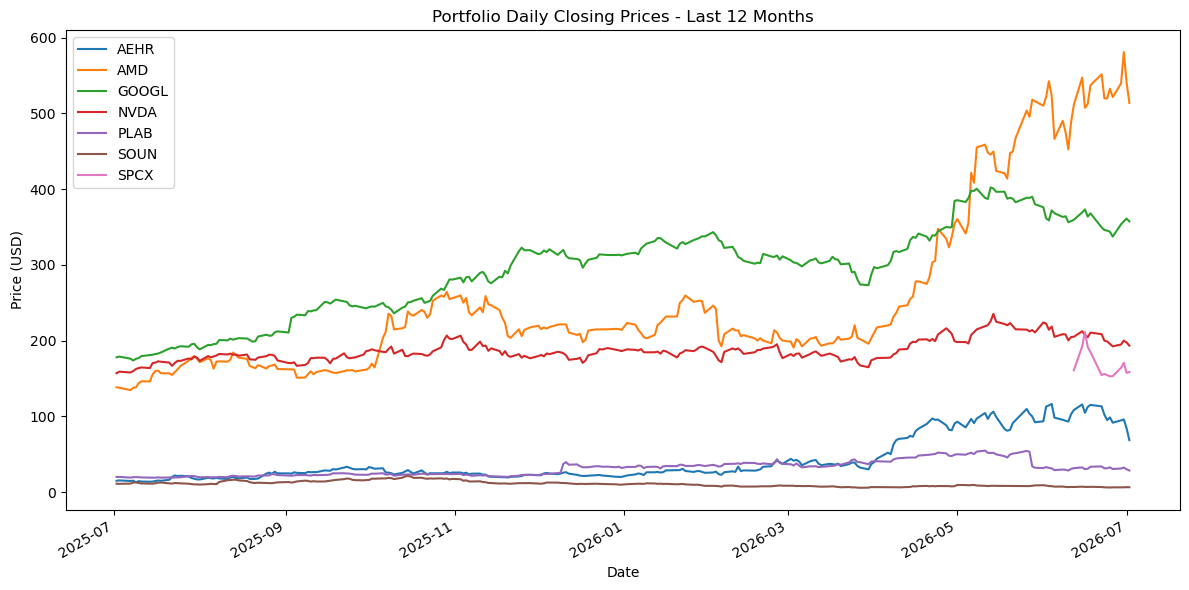

In [2]:
data.plot(figsize=(12, 6), title="Portfolio Daily Closing Prices - Last 12 Months")
plt.ylabel("Price (USD)")
plt.xlabel("Date")
plt.legend()
plt.tight_layout()
plt.show()

### 2.1.1 SpaceX — Since IPO

SpaceX went public on June 12, 2026 at $135/share, the largest IPO in history. It is plotted separately because only 2 weeks of trading history exist, making a fair comparison with other stocks impossible.

[*********************100%***********************]  1 of 1 completed


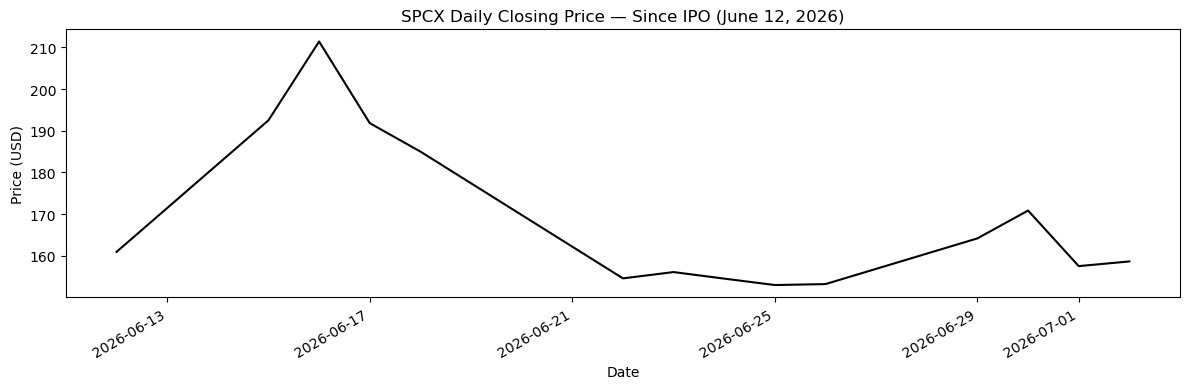

In [3]:
spcx_data = yf.download("SPCX", period="1mo")["Close"]

spcx_data.plot(figsize=(12, 4), title="SPCX Daily Closing Price — Since IPO (June 12, 2026)", color="black", legend=False)
plt.ylabel("Price (USD)")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

## 2.2 Relative Growth

To compare stocks fairly, all prices are normalized to start at 0%. This shows the percentage gain or loss since July 2025, regardless
of the original price. This makes it clear which stock performed best. SPCX is excluded due to limited trading history.

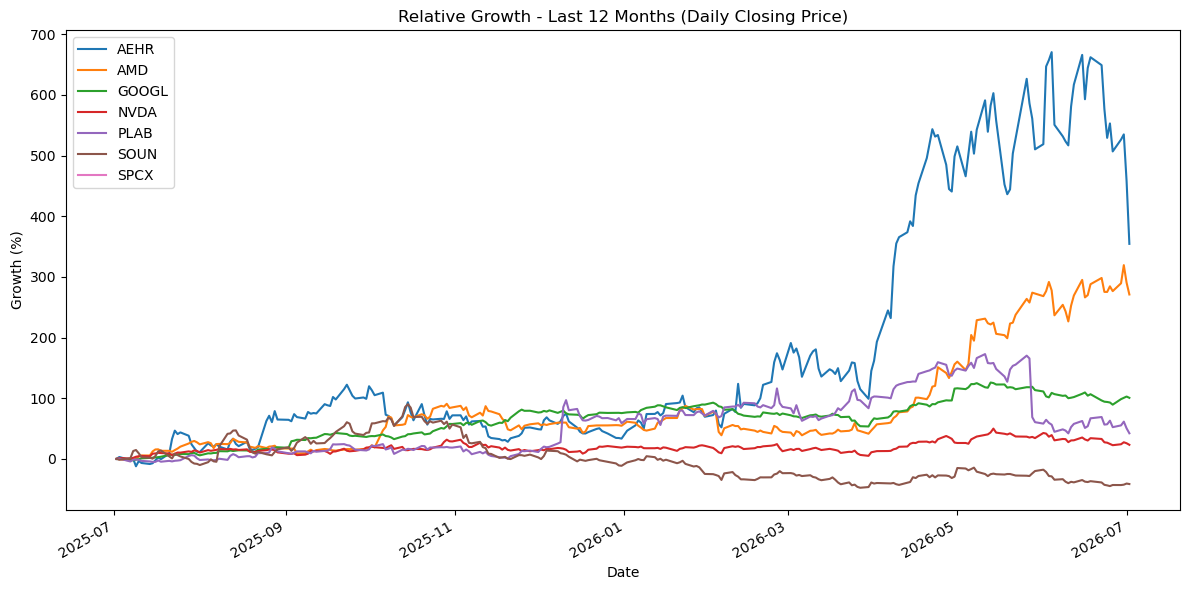

In [4]:
normalised = (data / data.iloc[0] - 1) * 100

normalised.plot(figsize=(12, 6), title="Relative Growth - Last 12 Months (Daily Closing Price)")
plt.ylabel("Growth (%)")
plt.xlabel("Date")
plt.legend()
plt.tight_layout()
plt.show()

## 2.3 Daily Returns

Daily returns show the percentage change in price from one day to the next. This is the foundation of all financial risk analysis. It shows not just how much a stock grew, but how volatile the journey was. (SPCX excluded)


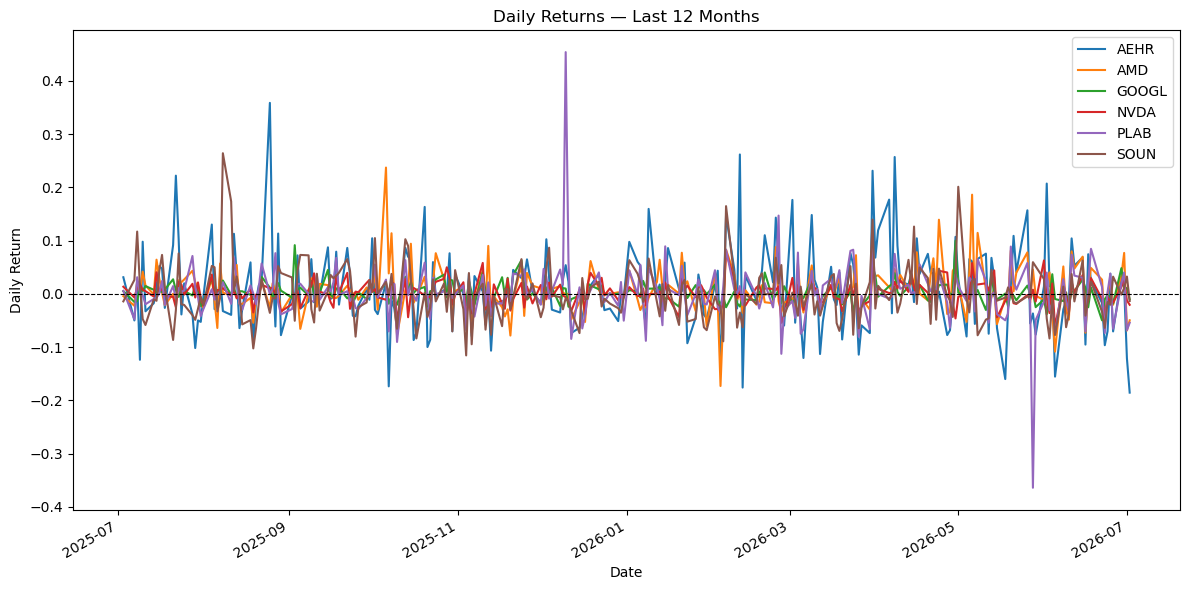

In [8]:
data_without_spcx = data.drop(columns=["SPCX"])
returns = data_without_spcx.pct_change().dropna()

returns.plot(figsize=(12, 6), title="Daily Returns — Last 12 Months")
plt.ylabel("Daily Return")
plt.xlabel("Date")
plt.legend()
plt.axhline(y=0, color="black", linewidth=0.8, linestyle="--")
plt.tight_layout()
plt.show()